GSEA, by cell type & stage for specific pathways

# Header

In [1]:
from utils import *

In [2]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [3]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch
from textwrap import fill

In [4]:
os.chdir('../')

In [5]:
import scanpy as sc
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [6]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

In [8]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

# Load data

In [8]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [9]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [10]:
for col in ['age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
    dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race',
       'group', 'diabetes', 'obesity'],
      dtype='object')

In [11]:
celltype_major = 'Mono'

In [12]:
d = dat[
    dat.obs['predicted.celltype.l1'] == celltype_major
]
d

View of AnnData object with n_obs × n_vars = 108864 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.stand

In [13]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=2
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

/tmp/ipykernel_3754236/3805644948.py:5: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  d.obsm['X_umap'] = umap.values


# Calc

In [14]:
len(d.obs['dataset_name'].unique())

55

## Overall

In [15]:
d_sub = d

sc.pp.neighbors(d_sub)

covars = ['race', 'age']
for v in ['obesity', 'diabetes']:
    if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
        covars.append(v)
        
samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                               covars,     # the metadata columns to use
                               'dataset_name')                        # the column of d.obs that contains sample IDs

samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]


res = cna.tl.association(
    d_sub,
    samplem.race, 
    'dataset_name',
    covs=samplem[[c for c in covars if c != 'race']],
    batches=samplem.batch,
    key_added='race_coef',
    return_full=True
)

/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global associati

In [16]:
pkl.dump(d_sub, 
         open('data/10_cna/Mono_cna.pkl', 'wb'))

In [17]:
pkl.dump(res, 
         open('data/10_cna/fullres_Mono.pkl', 'wb'))

## Cell type + Disease state

In [18]:
# change back
xcol = 'group'
d.obs['disease_state'] = ['HRL' if x==0 else 'DCIS' if x==1 else 'BC' for x in d.obs[xcol]]


In [20]:
for celltype in [
    'Classical Monocyte',
    'Intermediate Monocyte',
    'Nonclassical Monocyte',
    'Cytotoxic Monocyte'
]:
    for group in ['HRL','DCIS','BC']:
        
        d_sub = d[
        (d.obs['celltype_level3']==celltype) &
        (d.obs['disease_state']==group)
        ]
    
        sc.pp.neighbors(d_sub)

        covars = ['race', 'age']
        for v in ['obesity', 'diabetes']:
            if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
                covars.append(v)
                
        samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                       covars,     # the metadata columns to use
                                       'dataset_name')                        # the column of d.obs that contains sample IDs
        
        samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
        
        
        res = cna.tl.association(
            d_sub,
            samplem.race, 
            'dataset_name',
            covs=samplem[[c for c in covars if c != 'race']],
            batches=samplem.batch,
            key_added='race_coef',
            return_full=True
        )
    
        res = fast_spearman_ann(d_sub, 
                            obs_key='race_coef', 
                            genes=d_sub.var_names, chunk_size=2000)
    
        gene_corr_df = pd.DataFrame(res)
        
        pre_res1 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                             gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                             threads=1,
                             min_size=5,
                             max_size=1000,
                             permutation_num=1000, # reduce number to speed up testing
                             outdir=None, # don't write to disk
                             seed=1024,
                             verbose=True, # see what's going on behind the scenes
                            ).res2d
    
        pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                             gene_sets='data/11_genesets/immport_allgenelist.gmt',
                             threads=1,
                             min_size=5,
                             max_size=1000,
                             permutation_num=1000, # reduce number to speed up testing
                             outdir=None, # don't write to disk
                             seed=1024,
                             verbose=True, # see what's going on behind the scenes
                            ).res2d
    
        pre_res1.to_csv(f'data/Figure6/CNArankNHBvsW_{celltype}_{group}_hallmark.csv')
        pre_res2.to_csv(f'data/Figure6/CNArankNHBvsW_{celltype}_{group}_immport.csv')
        print(f'Done for {celltype}_{group}')
    


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2025-12-28 04:23:05,702 [WARNING] Duplicated values found in preranked stats: 10.57% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-28 04:23:05,704 [INFO] Parsing data files for GSEA.............................
2025-12-28 04:23:05,751 [INFO] 0000 gene_sets have been fi

Done for Classical Monocyte_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Classical Monocyte_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global association p-value attained minimal possible value. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2025-12-28 04:25:47,572 [

Done for Classical Monocyte_BC


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Intermediate Monocyte_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Intermediate Monocyte_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global associati

Done for Intermediate Monocyte_BC


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2025-12-28 04:29:12,111 [WARNING] Duplicated values found in preranked stats: 18.99% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-28 04:29:12,113 [INFO] Parsing data files for GSEA.............................
2025-12-28 04:29:12,152 [INFO] 0000 gene_sets have been fi

Done for Nonclassical Monocyte_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Nonclassical Monocyte_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global association p-value attained minimal possible value. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2025-12-28 04:31:27,234 [

Done for Nonclassical Monocyte_BC


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2025-12-28 04:32:14,323 [WARNING] Duplicated values found in preranked stats: 36.42% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-28 04:32:14,327 [INFO] Parsing data files for GSEA.............................
2025-12-28 04:32:14,400 [INFO] 0000 gene_sets have been fi

Done for Cytotoxic Monocyte_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Cytotoxic Monocyte_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for Cytotoxic Monocyte_BC


## Disease state

In [21]:
for group in ['HRL','DCIS','BC']:
    
    d_sub = d[
    (d.obs['disease_state']==group)
    ]

    sc.pp.neighbors(d_sub)

    covars = ['race', 'age']
    for v in ['obesity', 'diabetes']:
        if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
            covars.append(v)
            
    samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                   covars,     # the metadata columns to use
                                   'dataset_name')                        # the column of d.obs that contains sample IDs
    
    samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
    
    
    res = cna.tl.association(
        d_sub,
        samplem.race, 
        'dataset_name',
        covs=samplem[[c for c in covars if c != 'race']],
        batches=samplem.batch,
        key_added='race_coef',
        return_full=True
    )

    res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)

    gene_corr_df = pd.DataFrame(res)
    
    pre_res1 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/immport_allgenelist.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    pre_res1.to_csv(f'data/Figure6/CNArankNHBvsW_Mono_{group}_hallmark.csv')
    pre_res2.to_csv(f'data/Figure6/CNArankNHBvsW_Mono_{group}_immport.csv')
    print(f'Done for {group}')



/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global association p-value attained minimal possible value. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2025-12-28 04:42:10,672 [

Done for BC


# Analysis

## Overall

In [9]:
with open('data/10_cna/overall_Mono.pkl','rb') as f:
    d = pkl.load(f)

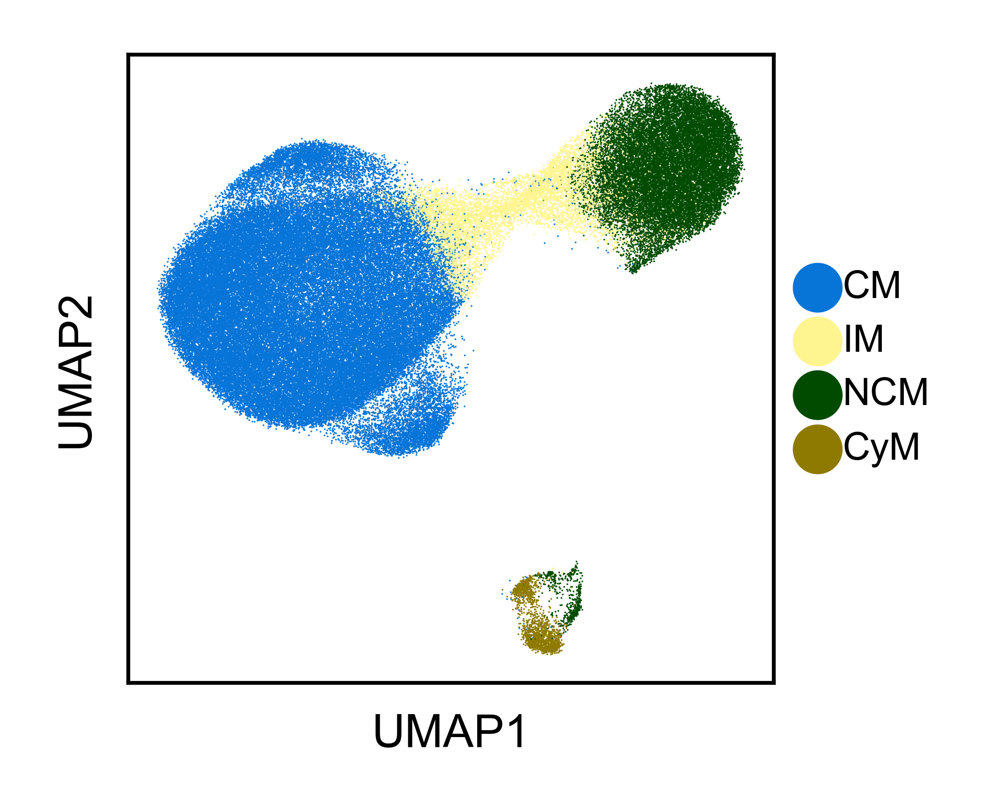

In [10]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'celltype_level3'
# cell_colors = {x: palsamplem['race-stage'] = samplem.apply(lambda row: f"{row['race']}-{row['group']}", axis=1)
# Counter(samplem['race-stage'])
#palette[ct] = (0.8, 0.8, 0.8)

order = cells_group['Mono']
pal_ordered = [palette_all[c] for c in order]

newlabel_dict = {
'Classical Monocyte': 'CM', 
'Intermediate Monocyte': 'IM', 
'Nonclassical Monocyte': 'NCM', 
'Cytotoxic Monocyte': 'CyM'
}

d.obs['celltype_level3_new'] = [
    newlabel_dict[x] for x in d.obs['celltype_level3']
]

d.obs['celltype_level3_new'] = pd.Categorical(
    d.obs['celltype_level3_new'],
    categories=[newlabel_dict[x] for x in order],
    ordered=True
)


sc.pl.umap(
    d,
    color='celltype_level3_new',
    palette=pal_ordered,
    size=.2,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6/Mono_celltype.svg')

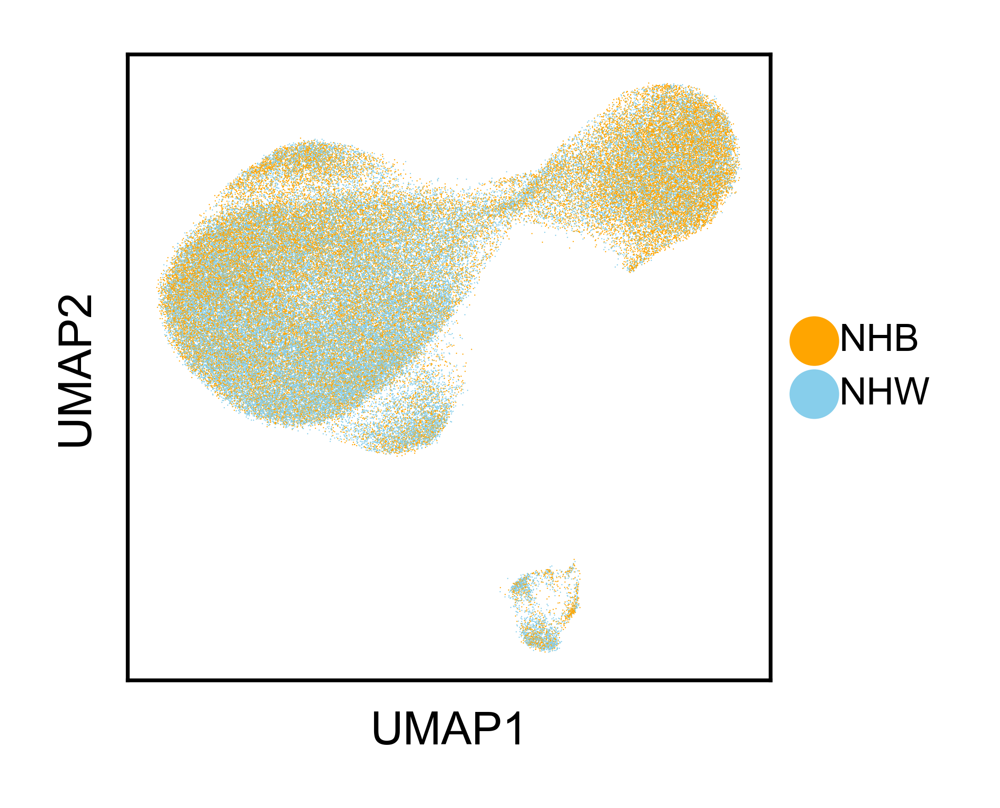

In [12]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race'
d.obs['race'] = [str(x).replace('1','NHB').replace('0','NHW') for x in d.obs['race']]


order = cells_group['Mono']
pal_ordered = [palette_all[c] for c in order]

sc.pl.umap(
    d,
    color=covar,
    palette=['orange','skyblue'],
    size=.1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6/Mono_race.svg')

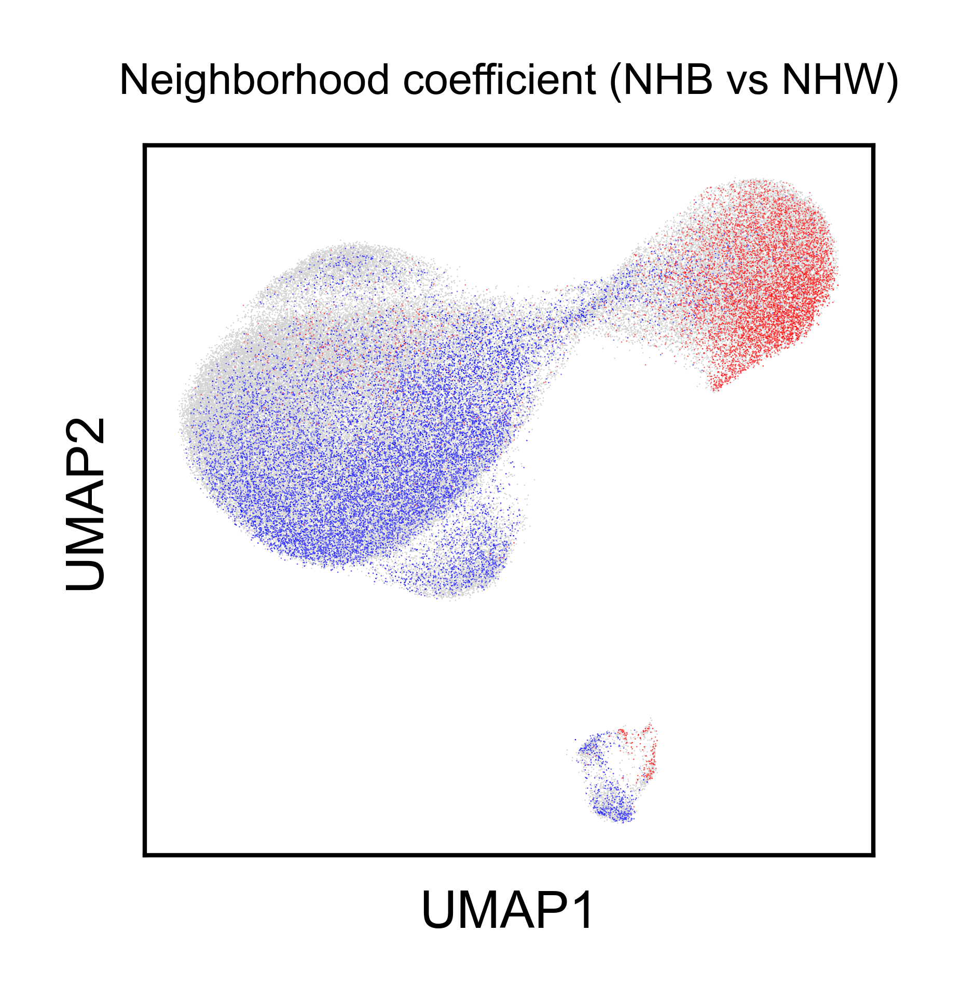

In [10]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"

d.obs[color_col] = np.where(d.obs[fdr_col] < 0.1, d.obs[coef_col], np.nan)   # nan will show as gray in sc.pl.umap
sc.pl.umap(
    d,
    color=color_col,
    s=.1,
    ax=ax,
    vmin=-1,
    vmax=1,
    cmap='seismic',
    na_color='lightgray',   # Gray for nan (non-significant)
    title='',
    colorbar_loc=None,
    show=False         # So you can further edit if needed
)

# cbar = ax.collections[0].colorbar
# ticks = [-1, -0.5, 0, 0.5, 1]
# cbar.set_ticks(ticks)
# cbar.set_ticklabels([str(t) for t in ticks])


ax.set_title('Neighborhood coefficient (NHB vs NHW)',fontsize=5)
plt.savefig('plots/F6/Mono_NbCoeff.svg')

In [11]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]>0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Nonclassical Monocyte: 6533 (88.30%)
Classical Monocyte: 552 (7.46%)
Intermediate Monocyte: 309 (4.18%)
Cytotoxic Monocyte: 5 (0.07%)


In [13]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]<0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Classical Monocyte: 14035 (87.42%)
Cytotoxic Monocyte: 423 (2.63%)
Intermediate Monocyte: 1231 (7.67%)
Nonclassical Monocyte: 365 (2.27%)


## Celltype + DzState

In [14]:
cts = 0

for celltype in [
    'Classical Monocyte',
    'Intermediate Monocyte',
    'Nonclassical Monocyte',
    'Cytotoxic Monocyte'
]:
    for group in ['HRL','DCIS','BC']:

        for db in ['hallmark','immport']:

            cts += 1
            
            raw = pd.read_csv(
                f'data/Figure6/CNArankNHBvsW_{celltype}_{group}_{db}.csv', 
                index_col=0)
            
            dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

            dfp['Tag %'] = (
                dfp['Tag %']
                .astype(str)
                .apply(lambda x: eval(x) if '/' in x else float(x))
            )
            dfp['Tag %'] = dfp['Tag %'] * 100
            dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))
            
            # Sort by NES
            dfp = dfp.sort_values('NES', ascending=False)
            
            # filter - 
            # dfp = dfp[dfp['Tag %']>=30]
            dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]

            dfp['analysis_celltype'] = [celltype]*dfp.shape[0]
            dfp['analysis_group'] = [group]*dfp.shape[0]
            dfp['analysis_db'] = [db]*dfp.shape[0]

            out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_celltype,analysis_group,analysis_db
2,prerank,INFLAMMATORY RESPONSE,0.685186,2.234320,0.000000,0.000000,0.000,37.628866,8.29%,ATP2B1;NAMPT;LYN;CD55;TNFRSF1B;BTG2;IL1B;PTPRE...,300.000000,Classical Monocyte,HRL,hallmark
3,prerank,TNFA SIGNALING VIA NFKB,0.639099,2.125194,0.000000,0.000000,0.000,41.708543,7.32%,ATP2B1;NAMPT;KYNU;TANK;BTG2;IL1B;PTPRE;NFE2L2;...,300.000000,Classical Monocyte,HRL,hallmark
4,prerank,MITOTIC SPINDLE,0.595069,1.955700,0.000000,0.000000,0.000,38.693467,12.74%,FGD4;DOCK2;NEDD9;PLEKHG2;PAFAH1B1;CCDC88A;MARC...,300.000000,Classical Monocyte,HRL,hallmark
7,prerank,UV RESPONSE DN,0.576665,1.818216,0.000000,0.000587,0.002,28.776978,7.89%,ATP2B1;SIPA1L1;NFKB1;ATXN1;SMAD3;NIPBL;ZMIZ1;A...,300.000000,Classical Monocyte,HRL,hallmark
11,prerank,KRAS SIGNALING DN,0.537990,1.726169,0.000000,0.002348,0.010,21.935484,15.79%,BTG2;CAMK1D;IFI44L;MX1;PTPRJ;NPHS1;CDKAL1;TG;R...,300.000000,Classical Monocyte,HRL,hallmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13,prerank,NATURAL KILLER CELL MEDIATED CYTOTOXICITY,-0.541448,-1.322483,0.095628,1.000000,0.989,31.250000,11.06%,SH2D1A;SLAMF7;KLRK1;LAG3;CD2;NKG7;STAT5B;TUBB4...,1.019413,Cytotoxic Monocyte,BC,immport
11,prerank,LYMPHOCYTE PROLIFERATION,-0.470995,-1.384727,0.011507,0.725117,0.926,42.342342,22.97%,CBLB;CCND3;SLAMF1;RPS6;PTPRC;CARD11;CD28;SH2D2...,1.939020,Cytotoxic Monocyte,BC,immport
10,prerank,ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY,-0.468018,-1.401962,0.010147,0.820119,0.897,33.766234,15.15%,NFATC2;PIK3CD;LCK;CBLB;SKAP1;KLHL6;CD247;PTPRC...,1.993681,Cytotoxic Monocyte,BC,immport
5,prerank,GAMMA-DELTA T CELL ACTIVATION,-0.702651,-1.541802,0.012802,0.266204,0.416,65.000000,16.70%,CD247;PTPRC;CD3E;CD3G;STAT5B;TCF7;CXADR;TRDC;I...,1.892713,Cytotoxic Monocyte,BC,immport


In [99]:
tmp = out[(out['FDR q-val']<0.1) & (out['analysis_db']=='immport')]
t1 = tmp[tmp['analysis_group']=='HRL']['Term'].tolist()
t2 = tmp[tmp['analysis_group']=='DCIS']['Term'].tolist()
t3 = tmp[tmp['analysis_group']=='BC']['Term'].tolist()

set(t1) & set(t2) & set(t3)

{'ANTIGEN PROCESSING AND PRESENTATION',
 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
 'B CELL ACTIVATION',
 'B CELL DIFFERENTIATION',
 'COMPLEMENT ACTIVATION',
 'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
 'COMPLEMENT CASCADE',
 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 'GROWTH HORMONE RECEPTOR SIGNALING',
 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
 'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
 'INTERFERON GAMMA SIGNALING',
 'INTERLEUKIN-2 FAMILY SIGNALING',
 'INTERLEUKIN-20 FAMILY SIGNALING',
 'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
 'INTERLEUKIN-6 FAMILY SIGNALING',
 'MHC CLASS II ANTIGEN PRESENTATION',
 'MYELOID LEUKOCYTE MIGRATION',
 'NATURAL KILLER CELL DIFFERENTIATION',
 'NEUTROPHIL DEGRANULATION',
 'RAP1 SIGNALLING',
 'TNFR2 NON-CANONICAL NF-KB PATHWAY'}

In [100]:
list_sel = [
'ANTIGEN PROCESSING AND PRESENTATION',
# 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
'MHC CLASS II ANTIGEN PRESENTATION',


'COMPLEMENT ACTIVATION',
'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
'COMPLEMENT CASCADE',


'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',


'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',

'INTERFERON ALPHA/BETA SIGNALING',
'INTERFERON GAMMA SIGNALING',
'INTERLEUKIN-6 FAMILY SIGNALING',

'MYELOID LEUKOCYTE MIGRATION',

]

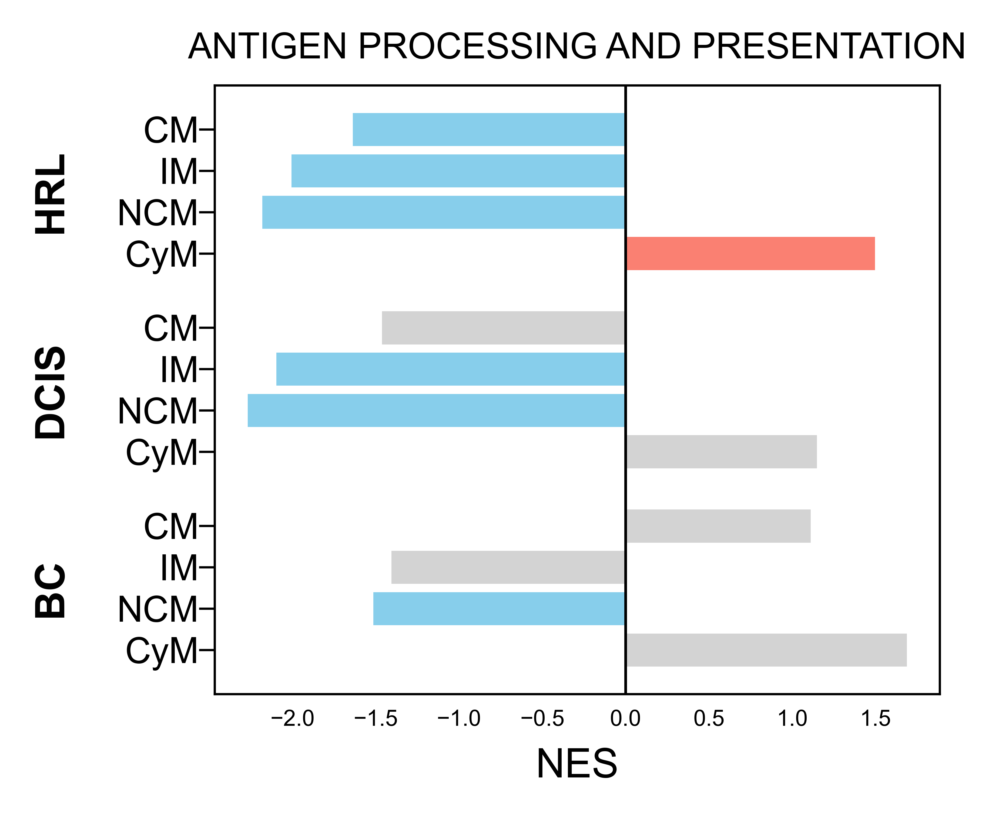

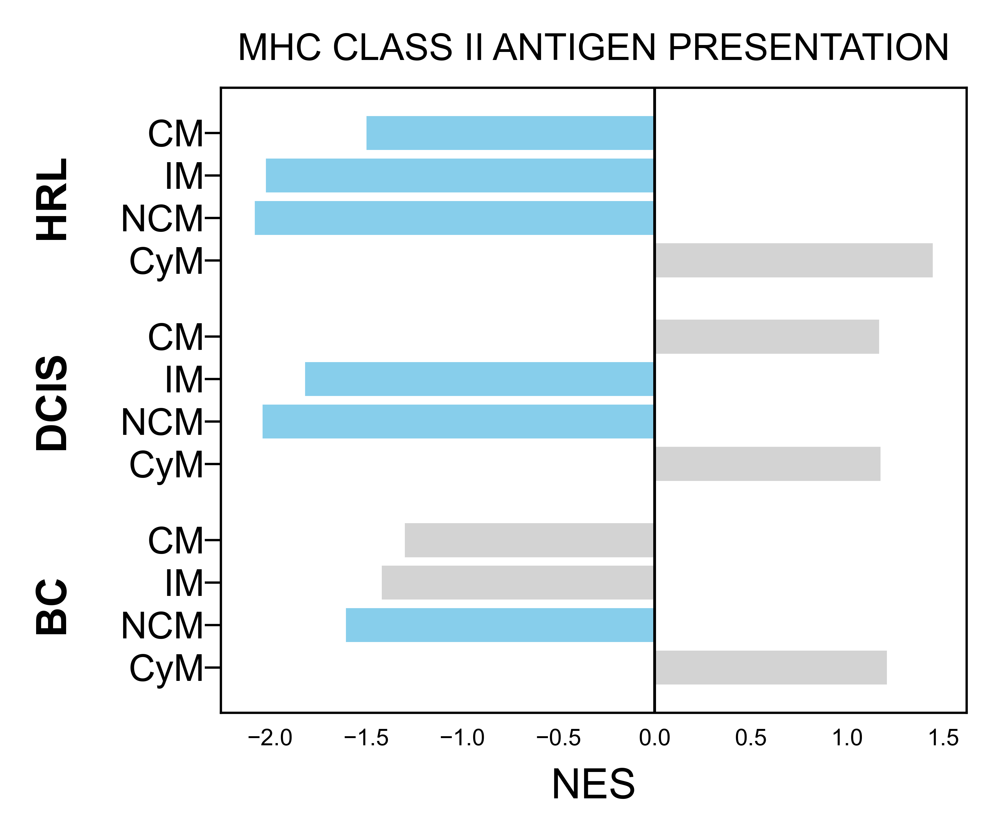

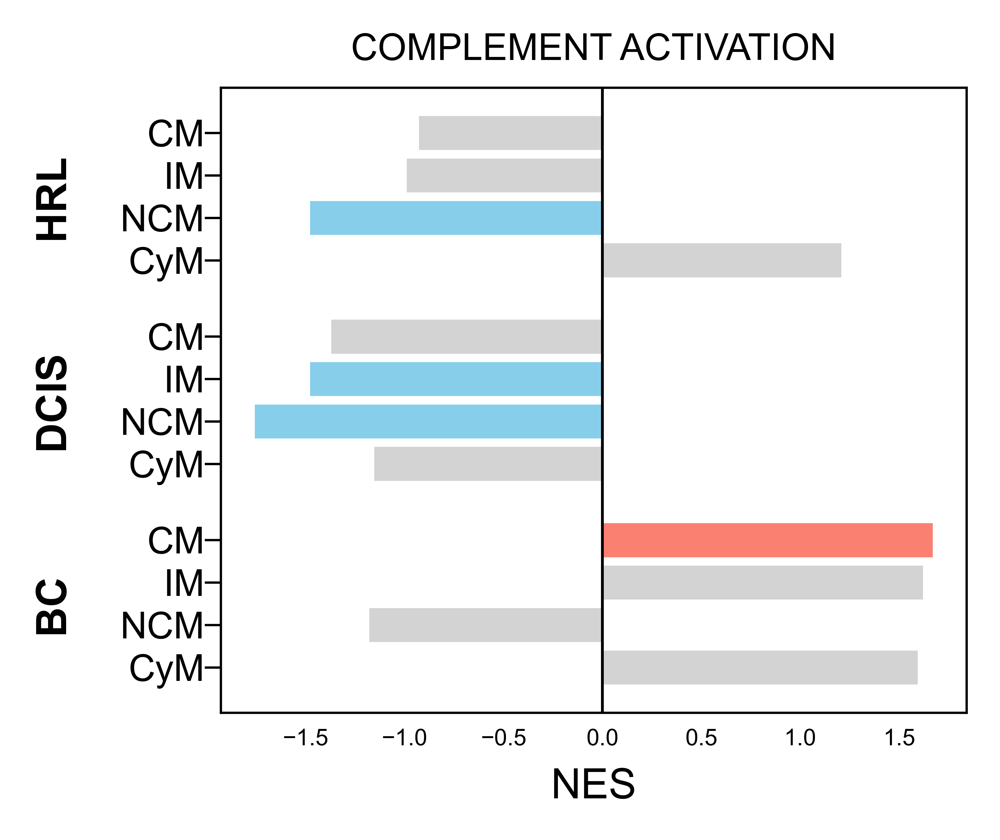

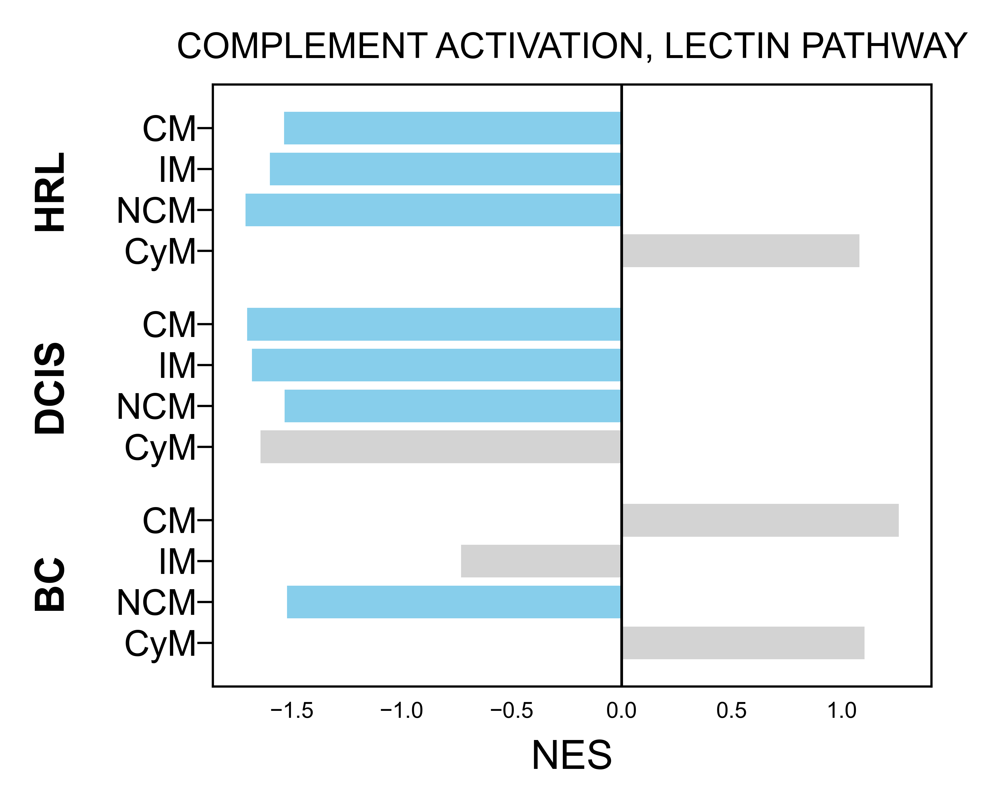

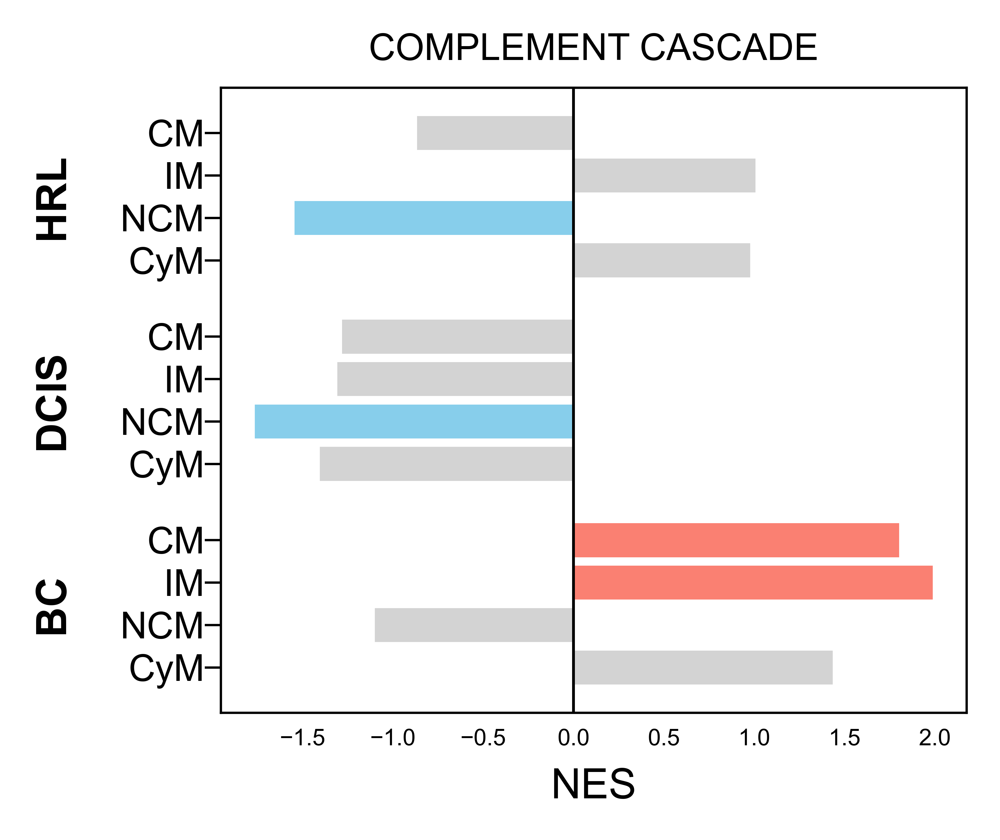

...

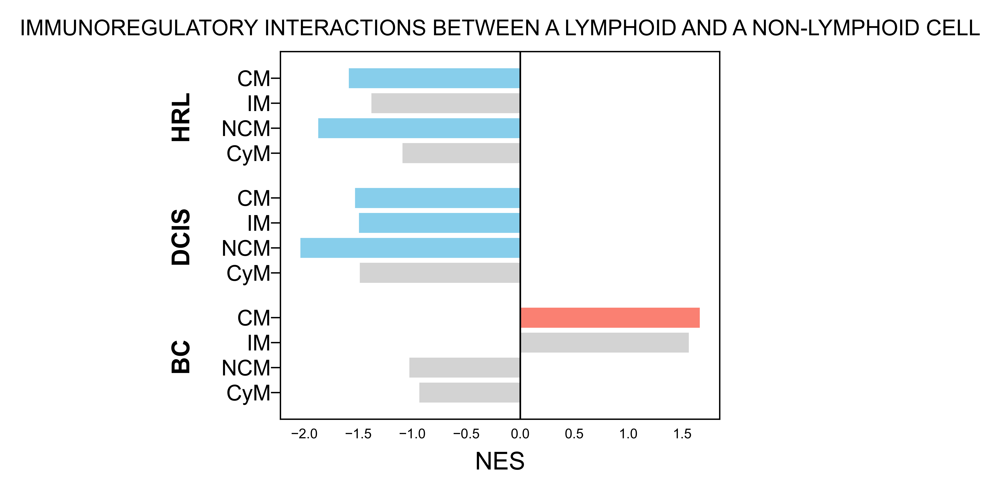

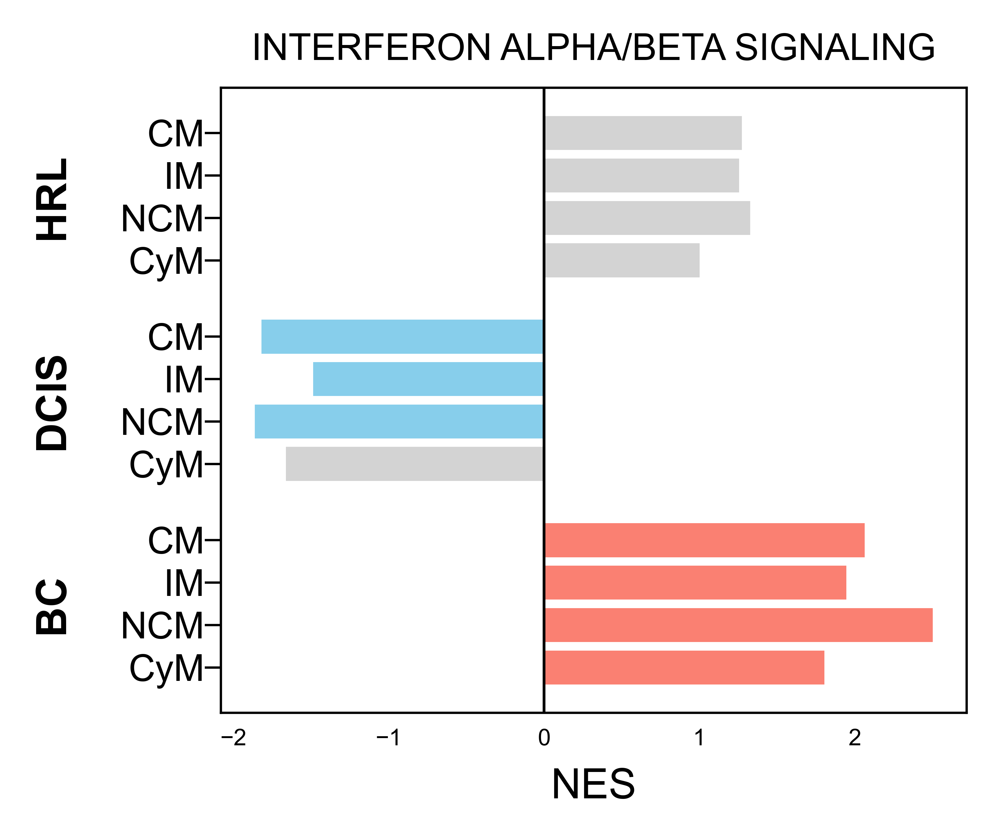

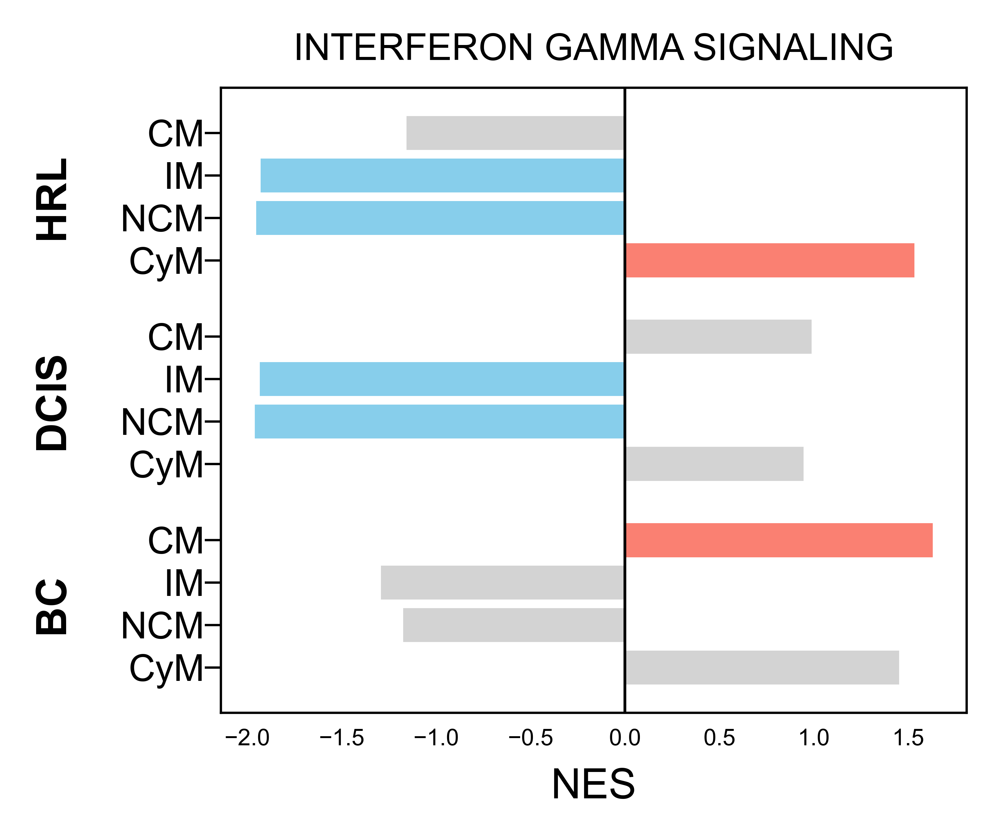

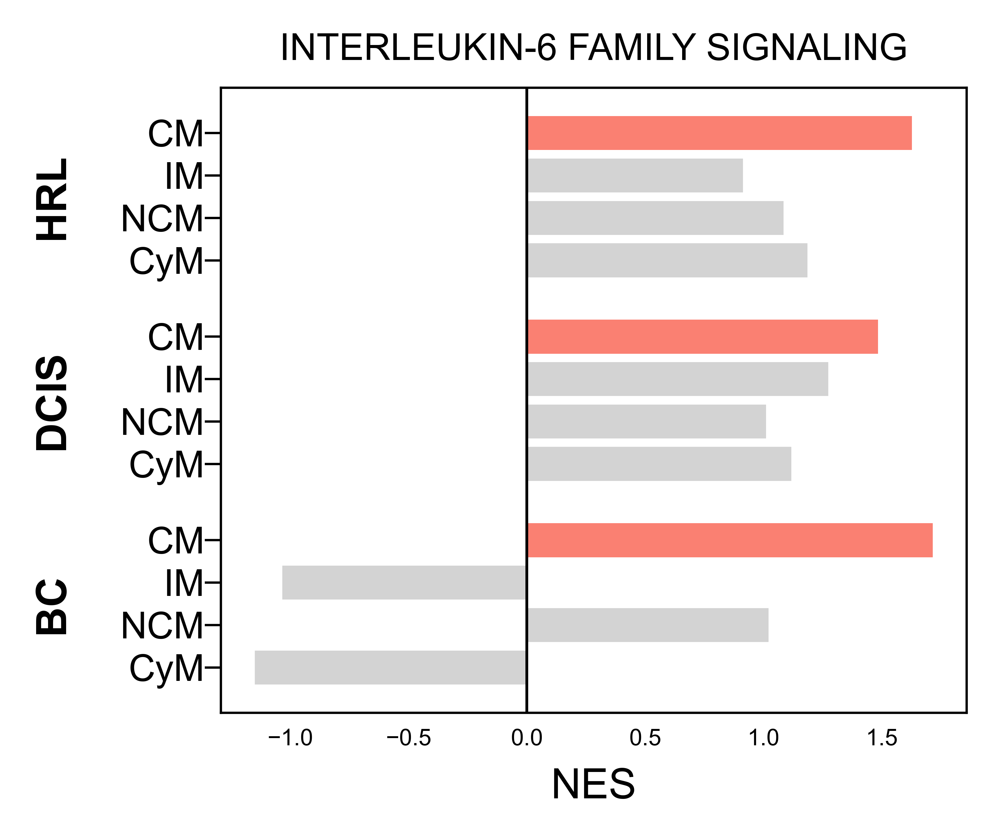

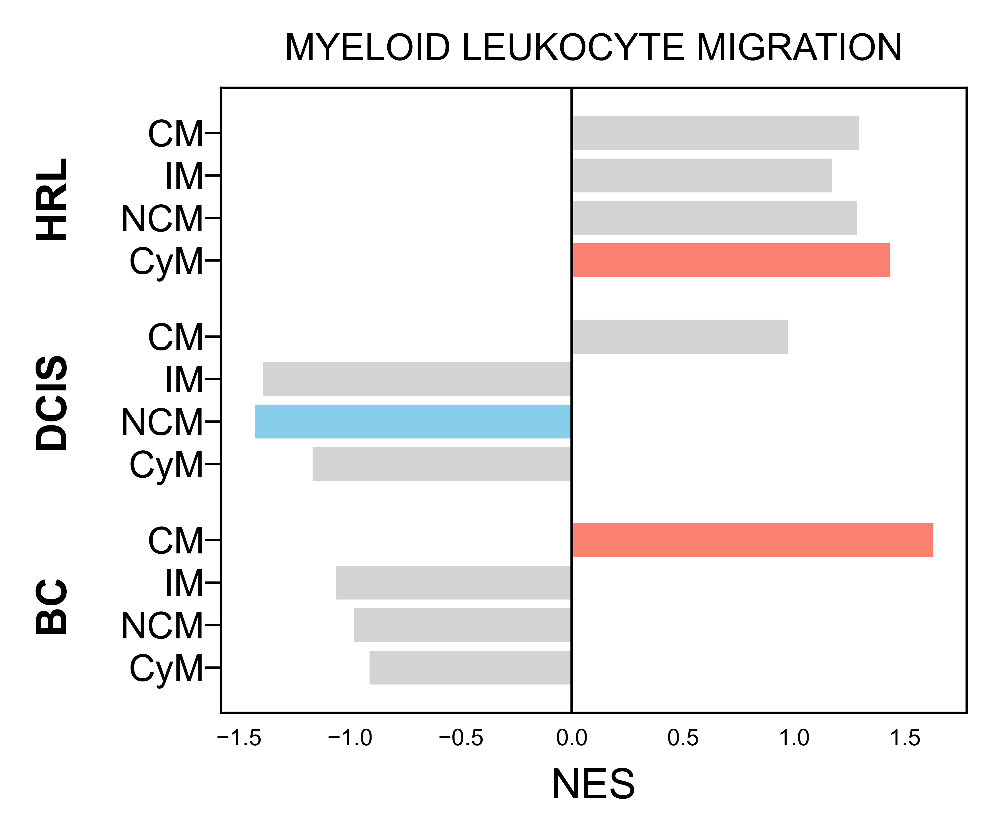

In [101]:
for path_sel in list_sel:
    
    dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
    qthres = .1
    
    abbr = {
        'Classical Monocyte': 'CM',
        'Intermediate Monocyte': 'IM',
        'Nonclassical Monocyte': 'NCM',
        'Cytotoxic Monocyte': 'CyM'
    }
    
    df = dfp.copy()
    df['ct'] = df['analysis_celltype'].map(abbr)
    
    group_order = df['analysis_group'].unique()
    ct_order = ['CM', 'IM', 'NCM', 'CyM']
    
    # ---- build plotting table ----
    rows = []
    y = 0
    gap = 0.8
    group_centers = {}
    
    for g in group_order:
        sub = df[df['analysis_group'] == g]
        start = y
        for ct in ct_order:
            r = sub[sub['ct'] == ct]
            if not r.empty:
                r = r.iloc[0]
                rows.append({
                    'y': y,
                    'NES': r['NES'],
                    'q': r['FDR q-val'],
                    'ct': ct,
                    'group': g
                })
                y += 1
        group_centers[g] = (start + y - 1) / 2
        y += gap
    
    plot_df = pd.DataFrame(rows)
    
    # ---- colors ----
    colors = [
        'salmon' if (q < qthres and nes > 0)
        else 'skyblue' if (q < qthres and nes < 0)
        else 'lightgray'
        for nes, q in zip(plot_df['NES'], plot_df['q'])
    ]
    
    # ---- plot ----
    fig, ax = plt.subplots(figsize=(3, 2.5))
    ax.barh(plot_df['y'], plot_df['NES'], color=colors)
    ax.axvline(0, color='black', lw=0.6)
    
    ax.set_title(path_sel, fontsize=8)
    ax.set_yticks(plot_df['y'])
    ax.set_yticklabels(plot_df['ct'], fontsize=8)
    
    # ---- group labels ----
    for g, yc in group_centers.items():
        ax.text(
            -0.2, yc, g,
            ha='right', va='center',
            fontsize=9, fontweight='bold',
            rotation=90,
            transform=ax.get_yaxis_transform()
        )
    
    ax.set_xlabel('NES', fontsize=9)
    ax.invert_yaxis()
    plt.tight_layout()
    
    # plt.savefig(f'plots/F6/Mono_{path_sel}.svg')

In [121]:
# finely-selected 3 pathways to show

list_sel = [
'ANTIGEN PROCESSING AND PRESENTATION',
# 'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
# 'MHC CLASS II ANTIGEN PRESENTATION',

'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
# 'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',

'MYELOID LEUKOCYTE MIGRATION',
    
'INTERFERON ALPHA/BETA SIGNALING',    
'COMPLEMENT ACTIVATION',
# 'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
# 'COMPLEMENT CASCADE',


# 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',


# 'INTERFERON GAMMA SIGNALING',
# 'INTERLEUKIN-6 FAMILY SIGNALING',

]

In [25]:
panel_title_map = {
    'ANTIGEN PROCESSING AND PRESENTATION': 'Antigen Presentation',
    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS': 'FcγR Phagocytosis Signaling',
    'COMPLEMENT ACTIVATION': 'Complement Activation',
    'MYELOID LEUKOCYTE MIGRATION': 'Myeloid Cell Migration',
    
    'INTERFERON ALPHA/BETA SIGNALING': 'Type I IFN Signaling',
}

In [26]:
panel_title_map.keys()

dict_keys(['ANTIGEN PROCESSING AND PRESENTATION', 'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS', 'COMPLEMENT ACTIVATION', 'MYELOID LEUKOCYTE MIGRATION', 'INTERFERON ALPHA/BETA SIGNALING'])

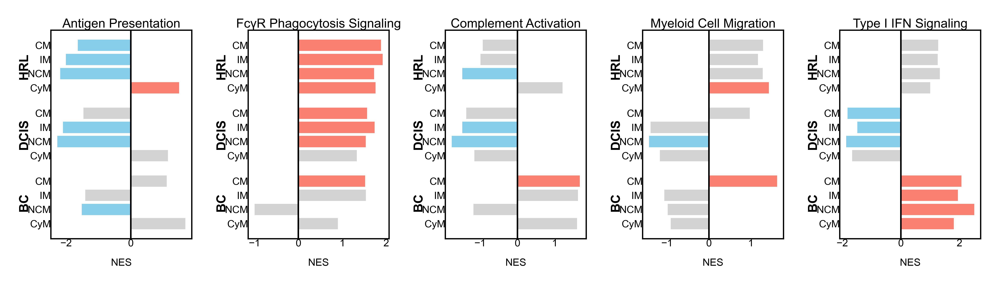

In [27]:
# make 1 row N columns
list_sel = panel_title_map.keys()
n = len(list_sel)
fig, axes = plt.subplots(
    1, n,
    figsize=(6.5, 1.5),   # scale width by number
    sharey=False
)

for ax, path_sel in zip(axes, list_sel):
    
    dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
    qthres = .1
    
    abbr = {
        'Classical Monocyte': 'CM',
        'Intermediate Monocyte': 'IM',
        'Nonclassical Monocyte': 'NCM',
        'Cytotoxic Monocyte': 'CyM'
    }
    
    df = dfp.copy()
    df['ct'] = df['analysis_celltype'].map(abbr)
    
    group_order = df['analysis_group'].unique()
    ct_order = ['CM', 'IM', 'NCM', 'CyM']
    
    # ---- build plotting table ----
    rows = []
    y = 0
    gap = 0.8
    group_centers = {}
    
    for g in group_order:
        sub = df[df['analysis_group'] == g]
        start = y
        for ct in ct_order:
            r = sub[sub['ct'] == ct]
            if not r.empty:
                r = r.iloc[0]
                rows.append({
                    'y': y,
                    'NES': r['NES'],
                    'q': r['FDR q-val'],
                    'ct': ct,
                    'group': g
                })
                y += 1
        group_centers[g] = (start + y - 1) / 2
        y += gap
    
    plot_df = pd.DataFrame(rows)
    
    # ---- colors ----
    colors = [
        'salmon' if (q < qthres and nes > 0)
        else 'skyblue' if (q < qthres and nes < 0)
        else 'lightgray'
        for nes, q in zip(plot_df['NES'], plot_df['q'])
    ]
    
    # ---- plot ----
    ax.barh(plot_df['y'], plot_df['NES'], color=colors)
    ax.axvline(0, color='black', lw=0.6)

    panel_title = panel_title_map[path_sel]
    ax.set_title(panel_title, fontsize=5, pad=1)

    ax.set_xlabel('NES', fontsize=4)
    ax.set_yticks(plot_df['y'])
    ax.set_yticklabels(plot_df['ct'], fontsize=4)
    
    # tick cosmetics
    ax.tick_params(axis='x', length=.2, labelsize=4)
    ax.tick_params(axis='y', length=0)   # remove tick length
    
    # group labels
    for g, yc in group_centers.items():
        ax.text(
            -0.15, yc, g,
            ha='right', va='center',
            fontsize=5, fontweight='bold',
            rotation=90,
            transform=ax.get_yaxis_transform()
        )
    
    ax.invert_yaxis()


plt.subplots_adjust(wspace=0.4)
plt.savefig('plots/F6/Mono_multiplot.svg')
plt.show()

In [30]:
path_sel = 'ANTIGEN PROCESSING AND PRESENTATION'
dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
12,Classical Monocyte,HRL,-1.636907,0.043394
28,Classical Monocyte,DCIS,-1.461553,0.125531
93,Classical Monocyte,BC,1.111387,0.363120
1,Intermediate Monocyte,HRL,-2.005010,0.000363
0,Intermediate Monocyte,DCIS,-2.095636,0.000000
23,Intermediate Monocyte,BC,-1.405136,0.329396
0,Nonclassical Monocyte,HRL,-2.181009,0.000000
0,Nonclassical Monocyte,DCIS,-2.268105,0.000000
8,Nonclassical Monocyte,BC,-1.513650,0.066384
15,Cytotoxic Monocyte,HRL,1.496023,0.091526


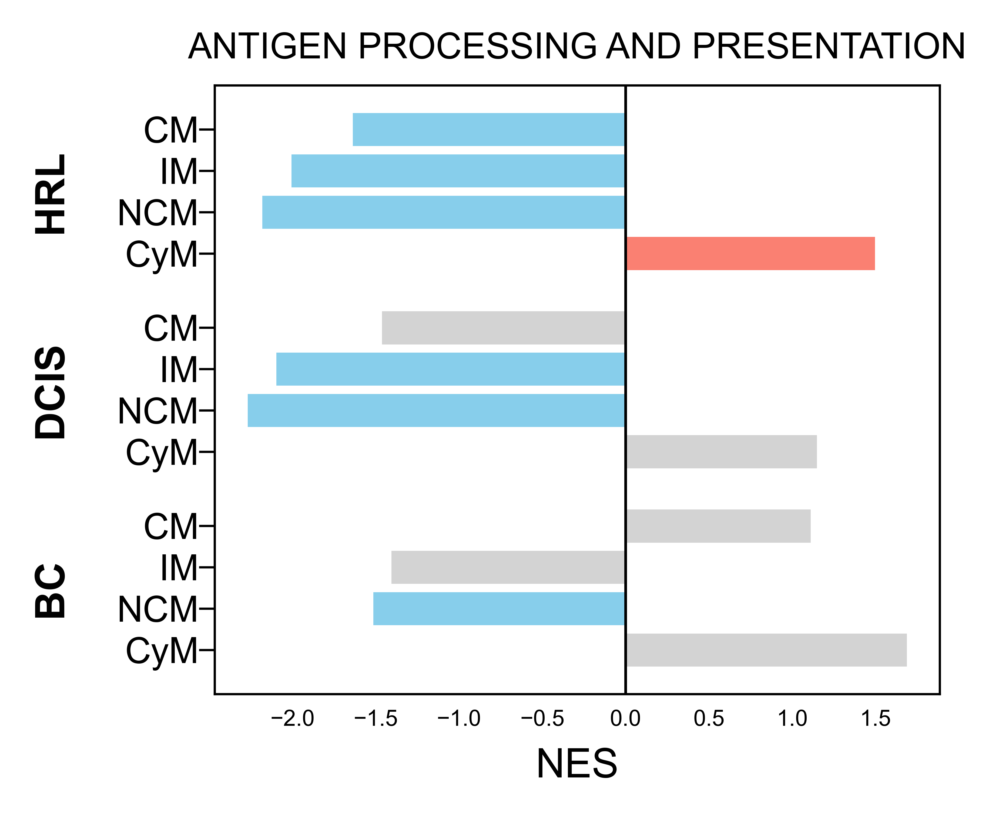

In [31]:
qthres = .1

abbr = {
    'Classical Monocyte': 'CM',
    'Intermediate Monocyte': 'IM',
    'Nonclassical Monocyte': 'NCM',
    'Cytotoxic Monocyte': 'CyM'
}

df = dfp.copy()
df['ct'] = df['analysis_celltype'].map(abbr)

group_order = df['analysis_group'].unique()
ct_order = ['CM', 'IM', 'NCM', 'CyM']

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.2, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

# plt.savefig(f'plots/F6/Mono_{path_sel}.svg')

In [16]:
path_sel = 'MITOTIC SPINDLE'

dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
4,Classical Monocyte,HRL,1.955700,0.000000
4,Classical Monocyte,DCIS,1.834448,0.000000
25,Classical Monocyte,BC,1.517721,0.014348
5,Intermediate Monocyte,HRL,1.769888,0.007249
3,Intermediate Monocyte,DCIS,1.934776,0.000375
44,Intermediate Monocyte,BC,-0.906619,0.826033
3,Nonclassical Monocyte,HRL,1.795667,0.010426
5,Nonclassical Monocyte,DCIS,1.968441,0.000000
22,Nonclassical Monocyte,BC,-1.165768,0.216683
6,Cytotoxic Monocyte,HRL,1.627027,0.004206


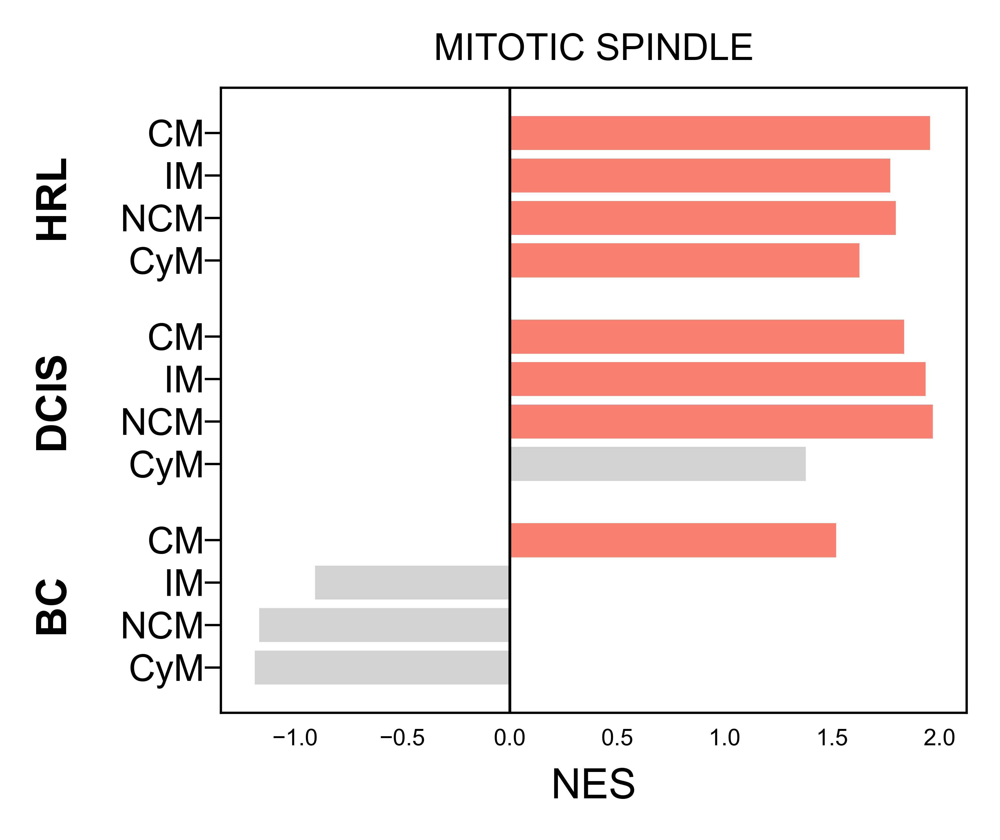

In [17]:
qthres = .1

abbr = {
    'Classical Monocyte': 'CM',
    'Intermediate Monocyte': 'IM',
    'Nonclassical Monocyte': 'NCM',
    'Cytotoxic Monocyte': 'CyM'
}

df = dfp.copy()
df['ct'] = df['analysis_celltype'].map(abbr)

group_order = df['analysis_group'].unique()
ct_order = ['CM', 'IM', 'NCM', 'CyM']

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.2, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F6/Mono_{path_sel}.svg')

In [26]:
path_sel = 'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY'#'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS'

dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
9,Classical Monocyte,HRL,1.681290,0.040309
33,Classical Monocyte,DCIS,1.385557,0.148166
11,Classical Monocyte,BC,1.683591,0.024184
2,Intermediate Monocyte,HRL,1.945581,0.001495
21,Intermediate Monocyte,DCIS,1.517687,0.069756
6,Intermediate Monocyte,BC,1.686811,0.070314
6,Nonclassical Monocyte,HRL,1.796576,0.043061
61,Nonclassical Monocyte,DCIS,1.300373,0.215881
89,Nonclassical Monocyte,BC,-0.966795,0.798630
1,Cytotoxic Monocyte,HRL,1.760417,0.006397


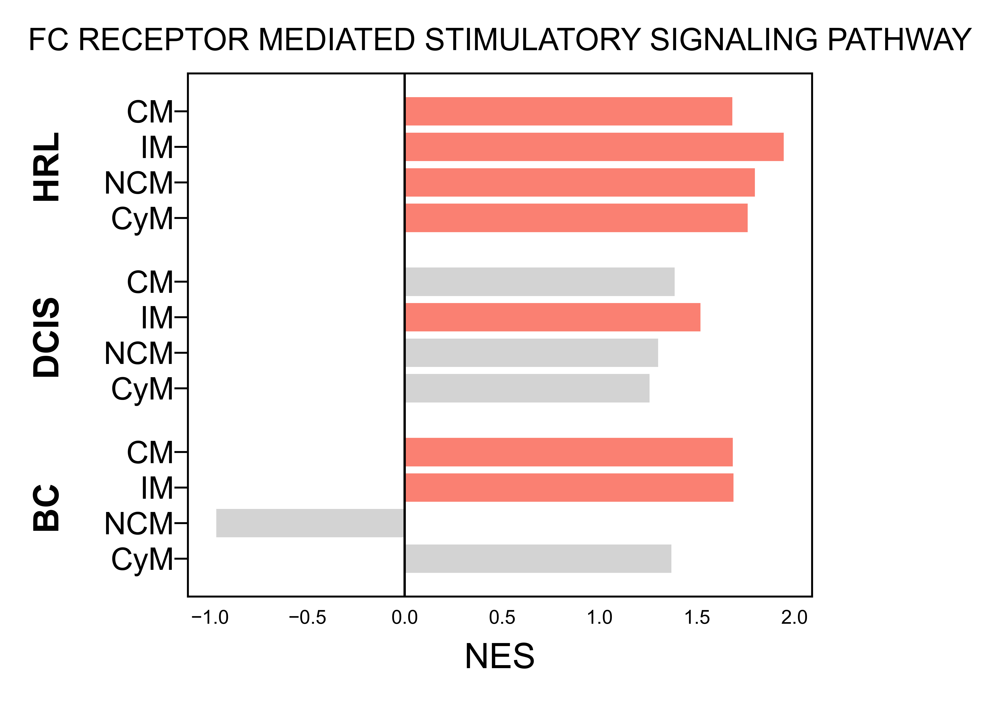

In [27]:
qthres = .1

abbr = {
    'Classical Monocyte': 'CM',
    'Intermediate Monocyte': 'IM',
    'Nonclassical Monocyte': 'NCM',
    'Cytotoxic Monocyte': 'CyM'
}

df = dfp.copy()
df['ct'] = df['analysis_celltype'].map(abbr)

group_order = df['analysis_group'].unique()
ct_order = ['CM', 'IM', 'NCM', 'CyM']

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, 
             fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.2, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F6/Mono_{path_sel}.svg')

In [28]:
path_sel = 'INTERFERON ALPHA RESPONSE'

dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
dfp

,analysis_celltype,analysis_group,NES,FDR q-val
29,Classical Monocyte,HRL,1.317578,0.098434
0,Classical Monocyte,DCIS,-2.303074,0.000000
5,Classical Monocyte,BC,2.221504,0.000000
34,Intermediate Monocyte,HRL,1.098966,0.282122
6,Intermediate Monocyte,DCIS,-1.674427,0.006077
0,Intermediate Monocyte,BC,2.062050,0.000000
29,Nonclassical Monocyte,HRL,-1.310174,0.085232
1,Nonclassical Monocyte,DCIS,-2.249474,0.000000
1,Nonclassical Monocyte,BC,1.671744,0.000000
16,Cytotoxic Monocyte,HRL,1.331768,0.085530


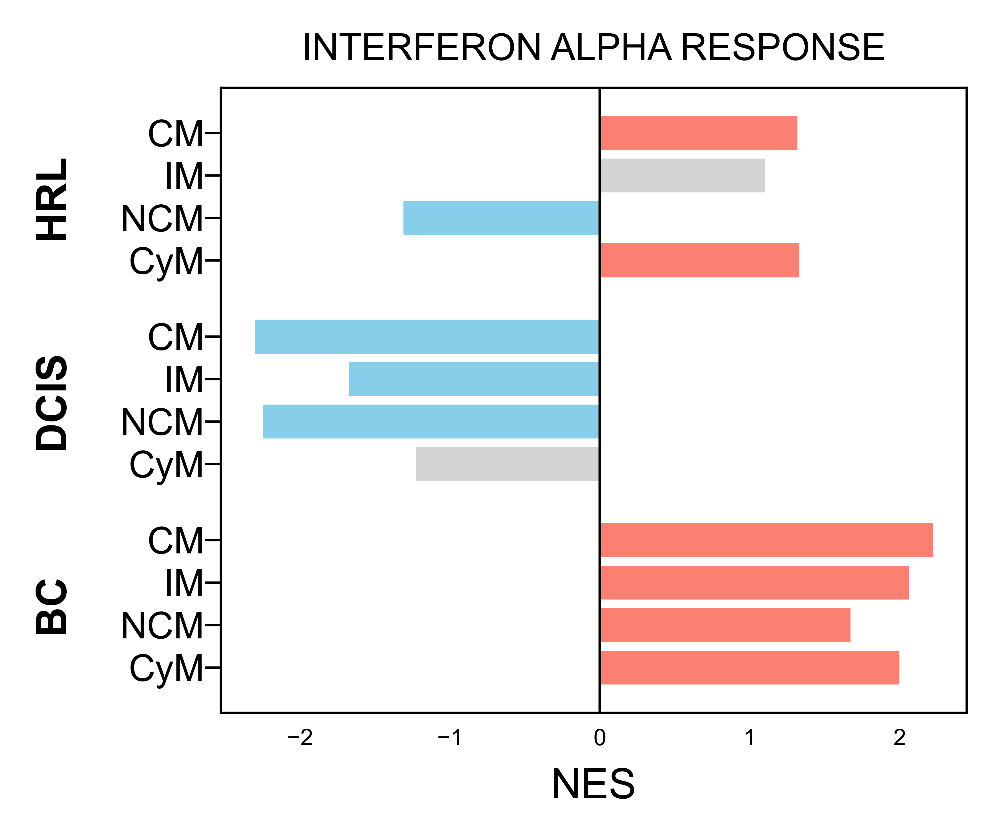

In [29]:
qthres = .1

abbr = {
    'Classical Monocyte': 'CM',
    'Intermediate Monocyte': 'IM',
    'Nonclassical Monocyte': 'NCM',
    'Cytotoxic Monocyte': 'CyM'
}

df = dfp.copy()
df['ct'] = df['analysis_celltype'].map(abbr)

group_order = df['analysis_group'].unique()
ct_order = ['CM', 'IM', 'NCM', 'CyM']

# ---- build plotting table ----
rows = []
y = 0
gap = 0.8
group_centers = {}

for g in group_order:
    sub = df[df['analysis_group'] == g]
    start = y
    for ct in ct_order:
        r = sub[sub['ct'] == ct]
        if not r.empty:
            r = r.iloc[0]
            rows.append({
                'y': y,
                'NES': r['NES'],
                'q': r['FDR q-val'],
                'ct': ct,
                'group': g
            })
            y += 1
    group_centers[g] = (start + y - 1) / 2
    y += gap

plot_df = pd.DataFrame(rows)

# ---- colors ----
colors = [
    'salmon' if (q < qthres and nes > 0)
    else 'skyblue' if (q < qthres and nes < 0)
    else 'lightgray'
    for nes, q in zip(plot_df['NES'], plot_df['q'])
]

# ---- plot ----
fig, ax = plt.subplots(figsize=(3, 2.5))
ax.barh(plot_df['y'], plot_df['NES'], color=colors)
ax.axvline(0, color='black', lw=0.6)

ax.set_title(path_sel, fontsize=8)
ax.set_yticks(plot_df['y'])
ax.set_yticklabels(plot_df['ct'], fontsize=8)

# ---- group labels ----
for g, yc in group_centers.items():
    ax.text(
        -0.2, yc, g,
        ha='right', va='center',
        fontsize=9, fontweight='bold',
        rotation=90,
        transform=ax.get_yaxis_transform()
    )

ax.set_xlabel('NES', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(f'plots/F6/Mono_{path_sel}.svg')

## Disease state

In [22]:
cts = 0


for group in ['HRL','DCIS','BC']:

    for db in ['hallmark','immport']:

        cts += 1
        
        raw = pd.read_csv(
            f'data/Figure6/CNArankNHBvsW_Mono_{group}_{db}.csv', 
            index_col=0)
        
        dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

        dfp['Tag %'] = (
            dfp['Tag %']
            .astype(str)
            .apply(lambda x: eval(x) if '/' in x else float(x))
        )
        dfp['Tag %'] = dfp['Tag %'] * 100
        dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
        
        # Sort by NES
        dfp = dfp.sort_values('NES', ascending=False)
        
        # filter - 
        # dfp = dfp[dfp['Tag %']>=30]
        dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]


        dfp['analysis_group'] = [group]*dfp.shape[0]
        dfp['analysis_db'] = [db]*dfp.shape[0]

        out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
0,prerank,INTERFERON ALPHA RESPONSE,0.707928,1.831498,0.000000,0.000000,0.000,64.583333,13.50%,IFITM3;IFITM1;IFITM2;LY6E;OAS1;CD47;TENT5A;SP1...,300.000000,HRL,hallmark
1,prerank,MITOTIC SPINDLE,0.609626,1.675959,0.000000,0.001776,0.005,39.195980,12.20%,NEDD9;PDLIM5;DOCK2;WASF2;PCGF5;SSH2;RASA1;SEPT...,2.750454,HRL,hallmark
2,prerank,PANCREAS BETA CELLS,0.771913,1.666705,0.001403,0.001421,0.006,22.222222,4.64%,MAFB;AKT3;FOXO1;LMO2;ELP4;VDR,2.847364,HRL,hallmark
3,prerank,PROTEIN SECRETION,0.608660,1.560956,0.001172,0.010659,0.060,46.315789,12.17%,CTSC;SOD1;SCRN1;ADAM10;MAPK1;M6PR;ATP1A1;RAB2A...,1.972302,HRL,hallmark
5,prerank,E2F TARGETS,0.547683,1.521726,0.001087,0.018191,0.121,41.414141,18.37%,NAP1L1;MXD3;CKS1B;TMPO;JPT1;TUBB;NBN;STAG1;RBB...,1.740154,HRL,hallmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...
38,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.826907,-1.477298,0.072816,0.145651,0.727,16.666667,0.61%,FCN1,0.836688,BC,immport
32,prerank,ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE,-0.656736,-1.524528,0.033419,0.125133,0.582,35.000000,11.29%,RPL39;FAU;IL6R;RNASE2;TREX1;OTUD7B;NOD2,0.902629,BC,immport
18,prerank,INNATE IMMUNE RESPONSE IN MUCOSA,-0.807011,-1.670081,0.010840,0.037802,0.197,16.666667,0.38%,RPL39;FAU,1.422488,BC,immport
15,prerank,ANTIMICROBIAL PEPTIDES,-0.662724,-1.676692,0.003030,0.052604,0.186,25.714286,6.32%,LYZ;S100A8;S100A9;RNASE6;CCR2;CD4;BPI;ELANE;ATOX1,1.278984,BC,immport


In [23]:
tmp = out[(out['FDR q-val']<0.1) & (out['analysis_db']=='immport')]

In [24]:
list_sel = [
'ANTIGEN PROCESSING AND PRESENTATION',
'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
'MHC CLASS II ANTIGEN PRESENTATION',


'COMPLEMENT ACTIVATION',
'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
'COMPLEMENT CASCADE',


'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',


'INTERFERON ALPHA/BETA SIGNALING',
'INTERFERON GAMMA SIGNALING',
'INTERLEUKIN-6 FAMILY SIGNALING',

'MYELOID LEUKOCYTE MIGRATION',

]

In [25]:
outtmp = pd.DataFrame()
for path_sel in list_sel:
    restmp = tmp[tmp['Term']==path_sel]
    outtmp = pd.concat((outtmp, restmp))

outtmp

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
32,prerank,ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY,0.542462,1.469494,0.002240,0.072506,0.723,27.922078,9.85%,LYN;PTPRC;CD79B;ADA;PTPN6;NFKBIZ;PTPRJ;LCP2;CS...,1.139625,HRL,immport
35,prerank,ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY,0.557574,1.391278,0.001011,0.095691,0.871,31.818182,11.64%,LYN;ADA;CD79B;PRKCB;PTPN6;PTPRJ;NFKBIZ;CSK;PTP...,1.019130,DCIS,immport
27,prerank,ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY,0.544033,1.575593,0.000000,0.025893,0.351,33.766234,12.50%,LYN;PTPRC;CD79B;ADA;PTPN6;CSK;PRKCB;LCP2;NFKBI...,1.586824,BC,immport
4,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.954008,-1.680730,0.000000,0.031173,0.157,16.666667,0.05%,FCN1,1.506218,HRL,immport
5,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.885776,-1.761571,0.004049,0.018599,0.056,16.666667,0.01%,FCN1,1.730506,DCIS,immport
21,prerank,COMPLEMENT CASCADE,0.665473,1.637870,0.007519,0.011602,0.150,23.913043,4.37%,CFD;C5AR1;CD55;CD81;C3;C5AR2;SERPING1;C1QA;C3A...,1.935455,BC,immport
11,prerank,FC RECEPTOR MEDIATED STIMULATORY SIGNALING PAT...,0.776118,1.629417,0.001361,0.022485,0.099,36.363636,5.94%,LYN;HCK;FCER1G;MYO1G;FGR;VAV1;PRKCE;FYN,1.648114,HRL,immport
9,prerank,FC RECEPTOR MEDIATED STIMULATORY SIGNALING PAT...,0.787749,1.648063,0.001166,0.004250,0.013,54.545455,13.16%,LYN;MYO1G;VAV2;PRKCE;VAV1;HCK;FGR;SRC;ABL1;NR4...,2.371657,DCIS,immport
16,prerank,FC RECEPTOR MEDIATED STIMULATORY SIGNALING PAT...,0.769554,1.675685,0.000000,0.006966,0.073,40.909091,3.93%,LYN;FCER1G;FGR;MYO1G;HCK;VAV1;PRKCE;VAV2;NR4A3,2.157025,BC,immport
18,prerank,FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED I...,0.763442,1.567819,0.006925,0.030186,0.281,35.000000,5.94%,LYN;HCK;MYO1G;FGR;VAV1;PRKCE;FYN,1.520192,HRL,immport


In [26]:
DzState, db = 'HRL', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['T CELL PROLIFERATION', 'ANTIVIRAL INNATE IMMUNE RESPONSE',
       'LYMPHOCYTE PROLIFERATION', 'INTERFERON ALPHA/BETA SIGNALING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'NATURAL KILLER CELL ACTIVATION', 'RAP1 SIGNALLING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'T CELL COSTIMULATION', 'B CELL ACTIVATION',
       'LYMPHOCYTE COSTIMULATION',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'B CELL DIFFERENTIATION', 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
       'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'COSTIMULATION BY THE CD28 FAMILY',
       'ANTIGEN RECEPTOR-MEDIATED 

In [27]:
paths_relevant = [
    # 'T CELL PROLIFERATION', 
    'ANTIVIRAL INNATE IMMUNE RESPONSE',
    # 'LYMPHOCYTE PROLIFERATION', 
    'INTERFERON ALPHA/BETA SIGNALING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'NATURAL KILLER CELL ACTIVATION', 
    'RAP1 SIGNALLING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'T CELL COSTIMULATION', 
    # 'B CELL ACTIVATION',
       # 'LYMPHOCYTE COSTIMULATION',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
    #    'B CELL DIFFERENTIATION', 
    # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE', 
    'DIAPEDESIS',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'LEUKOCYTE HOMEOSTASIS',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 4 SIGNALING PATHWAY',
       'FLT3 SIGNALING', 
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED IMMUNITY', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
       # 'TOLERANCE INDUCTION', 
    'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       # 'HUMORAL IMMUNE RESPONSE MEDIATED BY CIRCULATING IMMUNOGLOBULIN',
       'MYELOID LEUKOCYTE MIGRATION', 
       'LEUKOCYTE CHEMOTAXIS',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ANTIMICROBIAL PEPTIDES', 
    # 'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ANTIMICROBIAL HUMORAL RESPONSE'
]

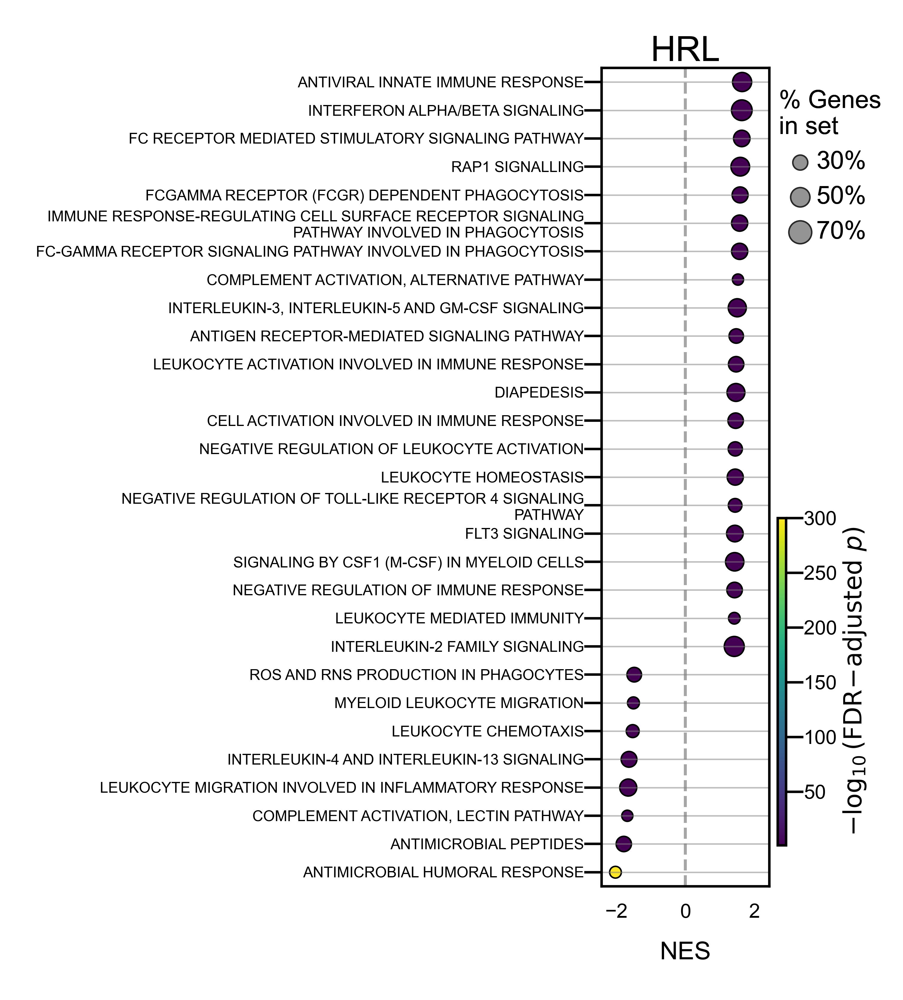

In [28]:
dfp2 = dfp[dfp['Term'].isin(paths_relevant)].reset_index(drop=True)

wrap_width = 60
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 3))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()

n_terms = dfp2.shape[0]
ax.set_ylim(n_terms - 0.5, -0.5)   # tighter top/bottom margins

# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=3)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)

ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)

# plt.tight_layout()
plt.savefig(f"plots/S6/Bubble_Mono_{DzState}_{db}.jpg", 
            dpi=600,
            bbox_inches='tight'
            )

In [29]:
DzState, db = 'DCIS', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS', 'FLT3 SIGNALING',
       'B CELL DIFFERENTIATION',
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       'NATURAL KILLER CELL ACTIVATION', 'B CELL ACTIVATION',
       'T CELL COSTIMULATION', 'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
       'RAP1 SIGNALLING', 'LYMPHOCYTE COSTIMULATION',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       'LYMPHOCYTE PROLIFERATION',
       'NATURAL KILLER CELL MEDIATED IMMUNITY', 'DIAPEDESIS',
       'T CELL PROLIFERATION', 'GROWTH HORMONE RECEPTOR SIGNALING',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)',
    

In [30]:
paths_relevant = [
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS', 
       'FLT3 SIGNALING',
       # 'B CELL DIFFERENTIATION',
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       # 'NATURAL KILLER CELL ACTIVATION', 
    # 'B CELL ACTIVATION',
    #    'T CELL COSTIMULATION', 
    # 'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
       'RAP1 SIGNALLING', 
    # 'LYMPHOCYTE COSTIMULATION',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'LYMPHOCYTE PROLIFERATION',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY', 
    'DIAPEDESIS',
    #    'T CELL PROLIFERATION', 
    # 'GROWTH HORMONE RECEPTOR SIGNALING',
    #    'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       # 'NATURAL KILLER CELL DIFFERENTIATION',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'TOLERANCE INDUCTION', 
    'MYELOID LEUKOCYTE MIGRATION',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'LEUKOCYTE CHEMOTAXIS', 
    'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ANTIMICROBIAL HUMORAL RESPONSE', 
    'ANTIMICROBIAL PEPTIDES'
]

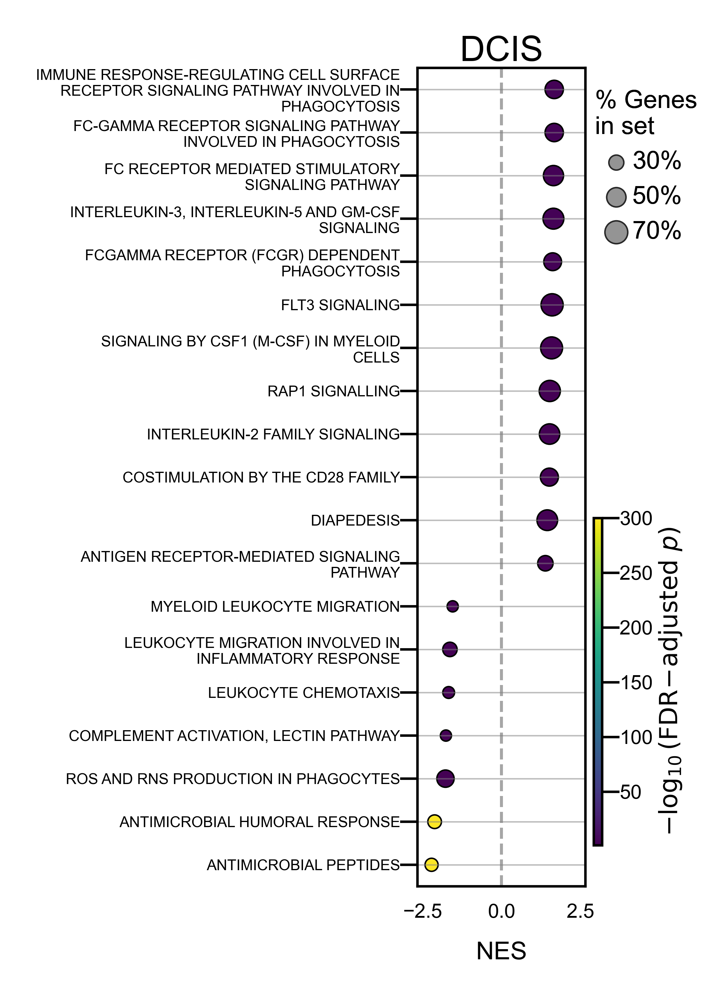

In [31]:
dfp2 = dfp[dfp['Term'].isin(paths_relevant)].reset_index(drop=True)


wrap_width = 40
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 3))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()
n_terms = dfp2.shape[0]
ax.set_ylim(n_terms - 0.5, -0.5)   # tighter top/bottom margins


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=3)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)

ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)

# plt.tight_layout()
plt.savefig(f"plots/S6/Bubble_Mono_{DzState}_{db}.jpg", 
            dpi=600,
            bbox_inches='tight'
            )

In [32]:
DzState, db = 'BC', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['INTERFERON ALPHA/BETA SIGNALING', 'LYMPHOCYTE COSTIMULATION',
       'T CELL COSTIMULATION', 'B CELL DIFFERENTIATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'NATURAL KILLER CELL ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'LEUKOCYTE MEDIATED IMMUNITY', 'B CELL ACTIVATION',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERFERON GAMMA SIGNALING', 'RAP1 SIGNALLING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'LYMPHOCYTE PROLIFERATION', 'TOLERANCE INDUCTION',
       'ANTIVIRAL INNATE IMMUNE RESPONSE', 'COMPLEMENT CASCADE',
       'T CELL PROLIFERATION',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'ANT

In [33]:
paths_relevant = [
'INTERFERON ALPHA/BETA SIGNALING', 
    # 'LYMPHOCYTE COSTIMULATION',
    #    'T CELL COSTIMULATION', 
    # 'B CELL DIFFERENTIATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'NATURAL KILLER CELL ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'LEUKOCYTE MEDIATED IMMUNITY', 
    # 'B CELL ACTIVATION',
       # 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERFERON GAMMA SIGNALING', 
    'RAP1 SIGNALLING',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       # 'LYMPHOCYTE PROLIFERATION', 
    # 'TOLERANCE INDUCTION',
       'ANTIVIRAL INNATE IMMUNE RESPONSE', 
    'COMPLEMENT CASCADE',
       # 'T CELL PROLIFERATION',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'ALPHA-BETA T CELL ACTIVATION',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       # 'ADAPTIVE IMMUNE RESPONSE BASED ON SOMATIC RECOMBINATION OF IMMUNE RECEPTORS BUILT FROM IMMUNOGLOBULIN SUPERFAMILY DOMAINS',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
       # 'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'DAP12 INTERACTIONS', 
    # 'NEUTROPHIL DEGRANULATION',
       'ANTIVIRAL MECHANISM BY IFN-STIMULATED GENES',
       # 'NATURAL KILLER CELL DIFFERENTIATION',
       'SIGNALING BY CSF1 (M-CSF) IN MYELOID CELLS',
       # 'T CELL MEDIATED CYTOTOXICITY', 
    'INTERLEUKIN-2 FAMILY SIGNALING',
       'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       'LEUKOCYTE HOMEOSTASIS', 
    # 'TCR SIGNALING',
       'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       'C-TYPE LECTIN RECEPTORS (CLRS)',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA', 
    'ANTIMICROBIAL PEPTIDES',
       'ANTIMICROBIAL HUMORAL RESPONSE'    
]

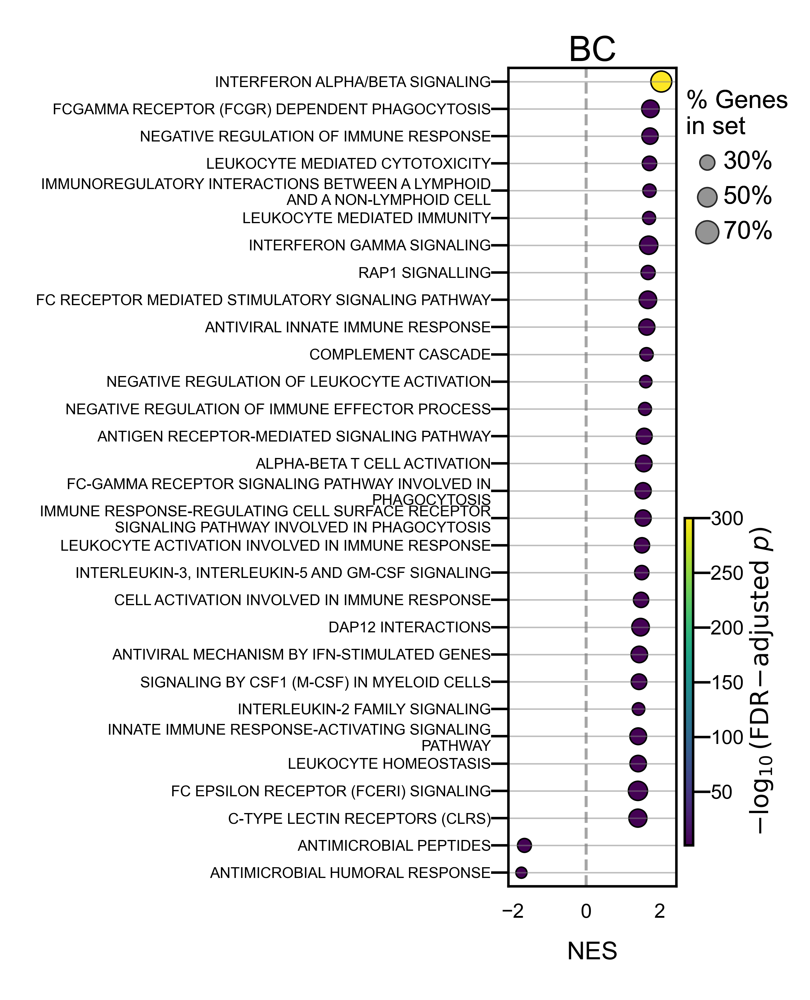

In [34]:
dfp2 = dfp[dfp['Term'].isin(paths_relevant)].reset_index(drop=True)


wrap_width = 50
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis

# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 3))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()
n_terms = dfp2.shape[0]
ax.set_ylim(n_terms - 0.5, -0.5)   # tighter top/bottom margins


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=3)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)

ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S6/Bubble_Mono_{DzState}_{db}.jpg", 
            dpi=600,
            bbox_inches='tight'
            )